In [2]:
import inspect
import os

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import statsmodels.api as sm

from itertools import combinations
from Regression_utils import *
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression


In [4]:
main_df = pd.read_excel(r"C:\Users\jroland\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Derived All Data.xlsx")
print(main_df.columns)

Index(['Name', 'Year-Month', 'Hours', 'Water Total', 'PSI', 'Revenue',
       'Metered DM', 'Power Factor', 'Billed DM', 'Billing KWH', 'Fuel Rate',
       'Electrical Bill', 'Workover Info', 'Workover Cost', 'Pump Model',
       'Pump Number', 'Plunger Size', 'Install Date', 'Maintenance Cost',
       'Maintenance Comments', 'KWH per Barrel', 'Cost per KWH',
       'Electrical Cost per Barrel', 'Maintenance Cost per Barrel',
       'Workover Cost per Barrel', 'Revenue per Barrel', 'Income per Barrel',
       'Income', 'Total Cost', '6 Month Avg Water Total', '6 Month Avg KWH',
       '6 Month Avg Revenue', '6 Month Avg Income', '6 Month Avg Total Cost',
       '6 Month Avg KWH per Barrel Weighted', '6 Month Avg Cost per KWH',
       '6 Month Avg Electrical Cost per Barrel',
       '6 Month Avg Maintenance Cost per Barrel',
       '6 Month Avg Workover Cost per Barrel',
       '6 Month Avg Revenue per Barrel', '6 Month Avg Income per Barrel',
       'Cumulative Electrical Cost', 'Cumul

In [6]:
# Double check that there are no problematic values for our data
print(main_df[main_df["PSI"].isna()])
print(np.isinf(main_df["PSI"]).sum())
print(main_df[main_df["Billing KWH"].isna()])
print(main_df["Billing KWH"].isna().sum())
print(np.isinf(main_df["Billing KWH"]).sum())

Empty DataFrame
Columns: [Name, Year-Month, Hours, Water Total, PSI, Revenue, Metered DM, Power Factor, Billed DM, Billing KWH, Fuel Rate, Electrical Bill, Workover Info, Workover Cost, Pump Model, Pump Number, Plunger Size, Install Date, Maintenance Cost, Maintenance Comments, KWH per Barrel, Cost per KWH, Electrical Cost per Barrel, Maintenance Cost per Barrel, Workover Cost per Barrel, Revenue per Barrel, Income per Barrel, Income, Total Cost, 6 Month Avg Water Total, 6 Month Avg KWH, 6 Month Avg Revenue, 6 Month Avg Income, 6 Month Avg Total Cost, 6 Month Avg KWH per Barrel Weighted, 6 Month Avg Cost per KWH, 6 Month Avg Electrical Cost per Barrel, 6 Month Avg Maintenance Cost per Barrel, 6 Month Avg Workover Cost per Barrel, 6 Month Avg Revenue per Barrel, 6 Month Avg Income per Barrel, Cumulative Electrical Cost, Cumulative Workover Cost, Cumulative Maintenance Cost, Cumulative Total Cost, Cumulative Income, Cumulative Revenue, 6 Month Avg Electrical Cost, 6 Month Avg Maintenance

<Axes: >

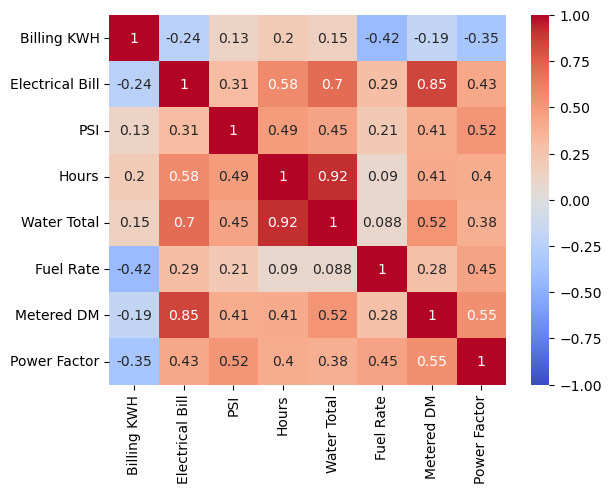

In [58]:
# basic correlation plot
corr_data = main_df[["Billing KWH", "Electrical Bill", "PSI", "Hours", "Water Total", "Fuel Rate", "Metered DM", "Power Factor"]]
corr_matrix = corr_data.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

In [40]:
# function for running OLS on an arbitrary number of variables
# returns the linear model whose output it summarizes
def get_ols(
    endog_vars: pd.DataFrame | pd.Series, 
    exog_vars: pd.DataFrame | pd.Series, 
    df: pd.DataFrame
) -> sm.regression.linear_model.OLS:
    
    # check that the Series being passed in are of the same length - pass for now
    endog = df[endog_vars]
    exog = df[exog_vars]
    exog = sm.add_constant(exog)

    # what we are comparing/regressing
    summary_stmt = f"{endog_vars} explained by {exog_vars} via linear regression"
    lm = sm.OLS(endog, exog).fit()
    print(summary_stmt, lm.summary())
    return lm

def plot_ols(
    endog_vars: pd.DataFrame | pd.Series,
    exog_vars: pd.DataFrame | pd.Series, 
    df: pd.DataFrame,
    linear_model: sm.regression.linear_model.OLS
) -> None:

    # plot data
    lm = linear_model
    fig, ax = plt.subplots()
    ax.scatter(endog_vars, exog_vars, label="Data")
    ax.plot(endog_vars, lm.fittedvalues, linestyle="--", label="Predicted")
    return None




In [ ]:
possible_exogs = ["PSI", "Billing KWH", "Hours", "Water Total", "Fuel Rate", "Metered DM", "Power Factor"]
# how to test every possible combination?
# how many combinations? n!/r!(n-r)! where r = # of choices
# We want to do every individual exog, every combination of 2, 3, 4, 5, 6, and 7 exogs
# comb(n=7, r=1) = 7, comb(n=7, r=2) = 7!/(2!*5!) = 21, comb(n=7, r=3) = 7!/(3!*4!) = 35,
# comb(n=7, r=4) = 7!/(4!*3!) = 35, comb(n=7, n=5) = comb(n=7, r=2) = 21, 
# comb(n=7, r=6) = comb(n=7, r=1) = 7, comb(n=7, r=7) = 1

# to get every possible combination, we need to call combinations(n, r) 
# for each value of r
for r in range(1, len(possible_exogs) + 1):
    for vars in combinations(exog_vars, r):
        # we'll need to do some filterings on our exog where there are 0 values.
        


C:\Users\jroland\AppData\Local\Temp\ipykernel_56404\1843911634.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\jroland\AppData\Local\Temp\ipykernel_56404\1843911634.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


      const         PSI
0       1.0  772.857143
1       1.0  777.142857
2       1.0  782.857143
3       1.0  774.285714
4       1.0  773.333333
...     ...         ...
8521    1.0  754.440000
8522    1.0  772.220000
8523    1.0  810.000000
8524    1.0    0.000000
8525    1.0    0.000000

[8526 rows x 2 columns] 0       125200.0
1       129440.0
2       148320.0
3       129440.0
4       127120.0
          ...   
8521     53040.0
8522     56400.0
8523     40560.0
8524        80.0
8525        40.0
Name: Billing KWH, Length: 8526, dtype: float64
Billing KWH explained by PSI                             OLS Regression Results                            
Dep. Variable:            Billing KWH   R-squared:                       0.017
Model:                            OLS   Adj. R-squared:                  0.017
Method:                 Least Squares   F-statistic:                     150.2
Date:                Tue, 15 Sep 2026   Prob (F-statistic):           3.08e-34
Time:                       

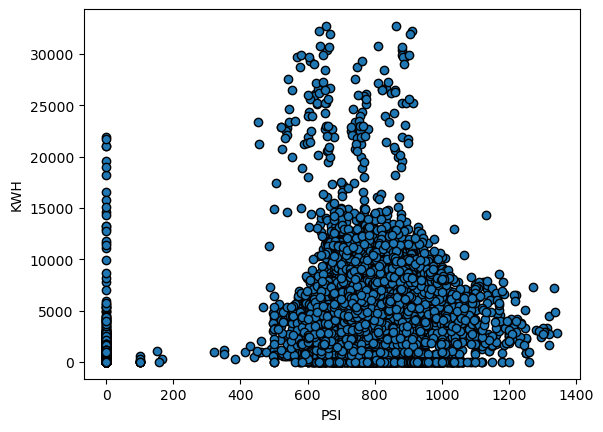

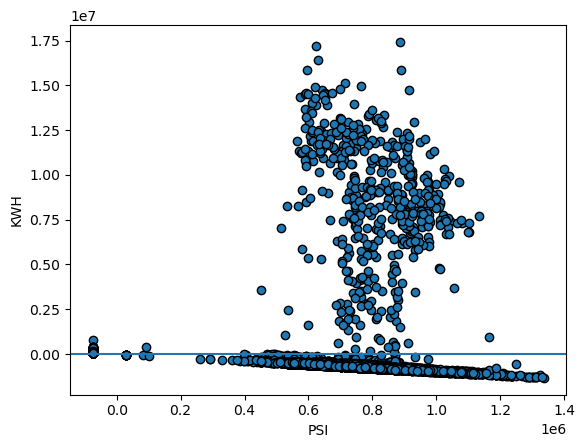

In [8]:
# psi vs billing kwh 
# It looks like readings of 0 PSI are causing issues
plt.ion()
fig, ax = plt.subplots()
ax.scatter(main_df["PSI"], main_df["Electrical Bill"], edgecolor="black")
ax.set_xlabel("PSI")
ax.set_ylabel("KWH")
fig.show()

# OLS for non-filtered data
exog = main_df["PSI"]
exog = sm.add_constant(exog)
endog = main_df["Billing KWH"]

print(exog, endog)
lm = sm.OLS(endog, exog).fit()
print("Billing KWH explained by PSI", lm.summary())

# plot fit vs residual data
fig, ax = plt.subplots()
ax.scatter(lm.fittedvalues, lm.resid, edgecolor="black")
ax.set_xlabel("PSI")
ax.set_ylabel("KWH")
ax.axhline(0)
fig.show()

C:\Users\jroland\AppData\Local\Temp\ipykernel_56404\2557941276.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\jroland\AppData\Local\Temp\ipykernel_56404\2557941276.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


      const         PSI
0       1.0  772.857143
1       1.0  777.142857
2       1.0  782.857143
3       1.0  774.285714
4       1.0  773.333333
...     ...         ...
8519    1.0  732.410000
8520    1.0  750.690000
8521    1.0  754.440000
8522    1.0  772.220000
8523    1.0  810.000000

[7348 rows x 2 columns] 0       125200.0
1       129440.0
2       148320.0
3       129440.0
4       127120.0
          ...   
8519     48600.0
8520     52080.0
8521     53040.0
8522     56400.0
8523     40560.0
Name: Billing KWH, Length: 7348, dtype: float64
Billing KWH explained by PSI                             OLS Regression Results                            
Dep. Variable:            Billing KWH   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     53.83
Date:                Tue, 15 Sep 2026   Prob (F-statistic):           2.42e-13
Time:                       

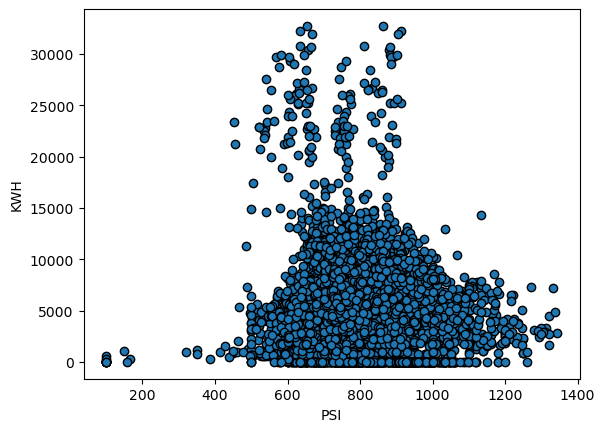

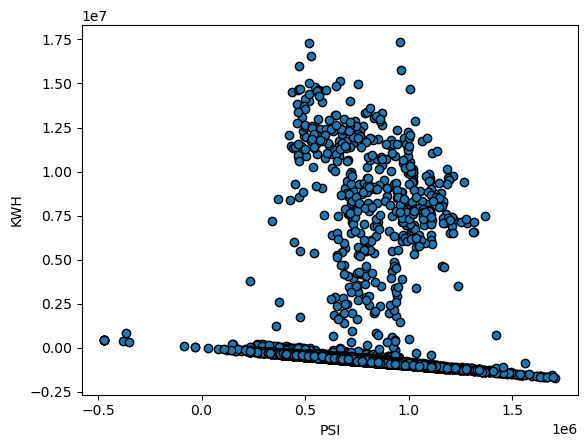

In [10]:
# filtered PSI vs Billing KWH
filtered_df = main_df[main_df["PSI"] > 0]
fig, ax = plt.subplots()
ax.scatter(filtered_df["PSI"], filtered_df["Electrical Bill"], edgecolor="black")
ax.set_xlabel("PSI")
ax.set_ylabel("KWH")
fig.show()

# OLS for filtered data
exog = filtered_df["PSI"]
exog = sm.add_constant(exog)
endog = filtered_df["Billing KWH"]

print(exog, endog)
lm = sm.OLS(endog, exog).fit()
print("Billing KWH explained by PSI", lm.summary())

# plot fit vs residual for filtered data
fig, ax = plt.subplots()
ax.scatter(lm.fittedvalues, lm.resid, edgecolor="black")
ax.set_xlabel("PSI")
ax.set_ylabel("KWH")
fig.show()

# RESULT: poor fit. Durbin-Watson score of less than 2 indicates positive auto-correlation of the terms.
# NOTE: A Plot of residuals should show a random distribution around zero. The fact that we are not seeing this
# confirms that the data is not i.i.d.

Electrical bill costs explained by PSI                             OLS Regression Results                            
Dep. Variable:        Electrical Bill   R-squared:                       0.004
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     27.67
Date:                Wed, 02 Sep 2026   Prob (F-statistic):           1.48e-07
Time:                        12:34:19   Log-Likelihood:                -71872.
No. Observations:                7348   AIC:                         1.437e+05
Df Residuals:                    7346   BIC:                         1.438e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       7

C:\Users\jroland\AppData\Local\Temp\ipykernel_8596\2564635766.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


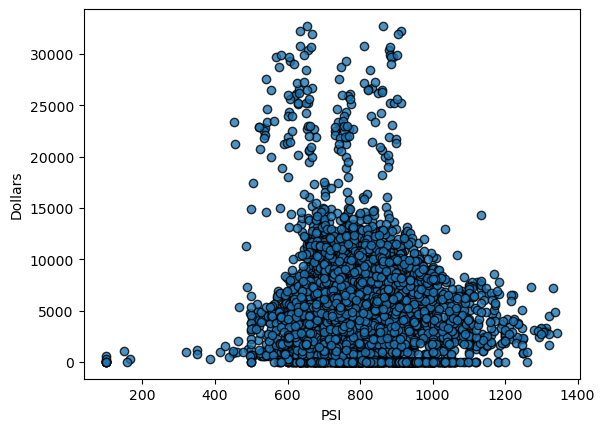

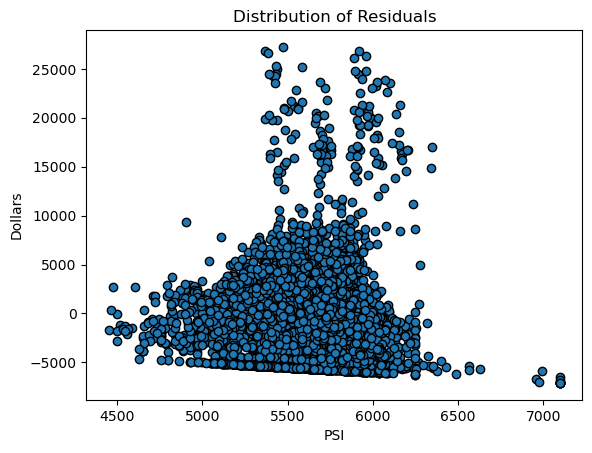

In [31]:
# electrical cost vs psi - using filtered data
filtered_df = main_df[main_df["PSI"] > 0]
endog = filtered_df["Electrical Bill"]
exog = filtered_df["PSI"]
exog = sm.add_constant(exog)
lm = sm.OLS(endog, exog).fit()
print("Electrical bill costs explained by PSI", lm.summary())

fig, ax = plt.subplots()
ax.scatter(filtered_df["PSI"], filtered_df["Electrical Bill"], edgecolor="black", alpha=0.8)
ax.set_xlabel("PSI")
ax.set_ylabel("Dollars")

fig, ax = plt.subplots()
ax.scatter(lm.fittedvalues, lm.resid, edgecolor="black")
ax.set_xlabel("PSI")
ax.set_ylabel("Dollars")
ax.set_title("Distribution of Residuals")
fig.show()

Electrical bill costs explained by Water Volume                             OLS Regression Results                            
Dep. Variable:        Electrical Bill   R-squared:                       0.505
Model:                            OLS   Adj. R-squared:                  0.505
Method:                 Least Squares   F-statistic:                     7036.
Date:                Tue, 15 Sep 2026   Prob (F-statistic):               0.00
Time:                        13:38:15   Log-Likelihood:                -64906.
No. Observations:                6905   AIC:                         1.298e+05
Df Residuals:                    6903   BIC:                         1.298e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
co

C:\Users\jroland\AppData\Local\Temp\ipykernel_56404\1904704873.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


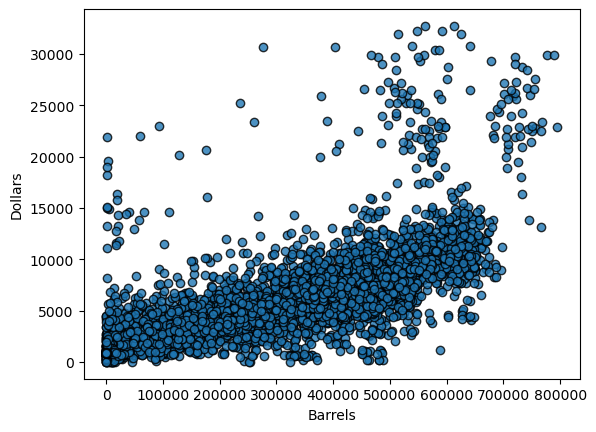

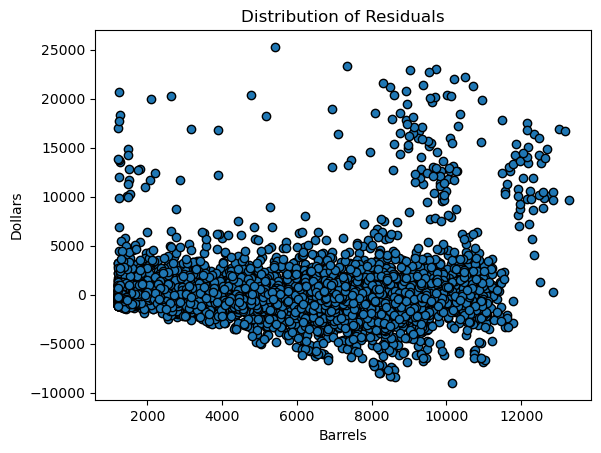

In [12]:
# electrical cost vs water total - using filtered data
water_filt = (main_df["Water Total"] > 0) & (main_df["Electrical Bill"] > 0)
filtered_df = main_df[water_filt]

endog = filtered_df["Electrical Bill"]
exog = filtered_df["Water Total"]
exog = sm.add_constant(exog)
lm = sm.OLS(endog, exog).fit()
print("Electrical bill costs explained by Water Volume", lm.summary())

fig, ax = plt.subplots()
ax.scatter(filtered_df["Water Total"], filtered_df["Electrical Bill"], edgecolor="black", alpha=0.8)
ax.set_xlabel("Barrels")
ax.set_ylabel("Dollars")

fig, ax = plt.subplots()
ax.scatter(lm.fittedvalues, lm.resid, edgecolor="black")
ax.set_xlabel("Barrels")
ax.set_ylabel("Dollars")
ax.set_title("Distribution of Residuals")
fig.show()

In [43]:
# kwh vs water total
endog = main_df["Billing KWH"]
exog = main_df["Water Total"]
exog = sm.add_constant(exog)
lm = sm.OLS(endog, exog).fit()
print("KWH explained by water volume", lm.summary())

KWH explained by water volume                             OLS Regression Results                            
Dep. Variable:            Billing KWH   R-squared:                       0.023
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     200.4
Date:                Wed, 02 Sep 2026   Prob (F-statistic):           5.50e-45
Time:                        12:54:32   Log-Likelihood:            -1.3715e+05
No. Observations:                8526   AIC:                         2.743e+05
Df Residuals:                    8524   BIC:                         2.743e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const        1.609e+

Electrical bill costs explained by PSI and run hours                             OLS Regression Results                            
Dep. Variable:        Electrical Bill   R-squared:                       0.326
Model:                            OLS   Adj. R-squared:                  0.326
Method:                 Least Squares   F-statistic:                     1673.
Date:                Tue, 15 Sep 2026   Prob (F-statistic):               0.00
Time:                        13:57:42   Log-Likelihood:                -65968.
No. Observations:                6905   AIC:                         1.319e+05
Df Residuals:                    6902   BIC:                         1.320e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------

C:\Users\jroland\AppData\Local\Temp\ipykernel_56404\2888010221.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


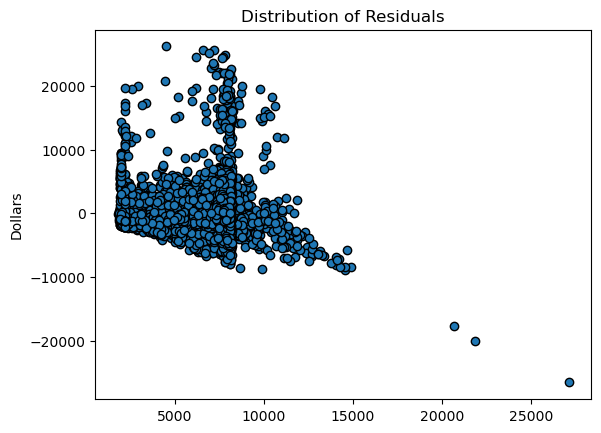

In [14]:
# billing kwh vs psi + hours - using filtered data
endog = filtered_df["Electrical Bill"]
exog = filtered_df[["PSI", "Hours"]]
exog = sm.add_constant(exog)
lm = sm.OLS(endog, exog).fit()
print("Electrical bill costs explained by PSI and run hours", lm.summary())

fig, ax = plt.subplots()
ax.scatter(lm.fittedvalues, lm.resid, edgecolor="black")
ax.set_ylabel("Dollars")
ax.set_title("Distribution of Residuals")
fig.show()

Electrical bill costs explained by PSI and run hours                             OLS Regression Results                            
Dep. Variable:        Electrical Bill   R-squared:                       0.524
Model:                            OLS   Adj. R-squared:                  0.524
Method:                 Least Squares   F-statistic:                     2531.
Date:                Wed, 02 Sep 2026   Prob (F-statistic):               0.00
Time:                        12:55:57   Log-Likelihood:                -64770.
No. Observations:                6905   AIC:                         1.295e+05
Df Residuals:                    6901   BIC:                         1.296e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------

C:\Users\jroland\AppData\Local\Temp\ipykernel_8596\3053826221.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


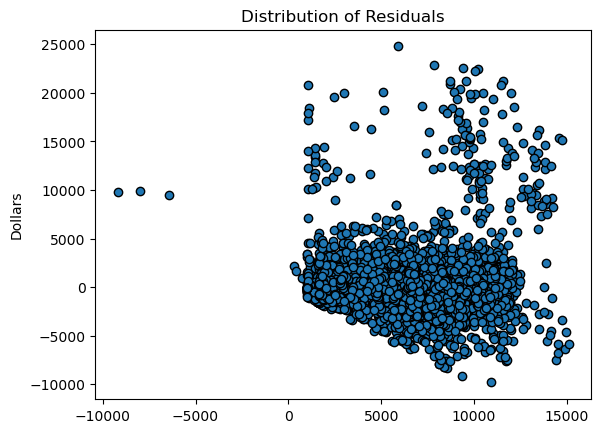

In [44]:
# electrical cost vs psi + hours + water total - using filtered data
endog = filtered_df["Electrical Bill"]
exog = filtered_df[["PSI", "Hours", "Water Total"]]
exog = sm.add_constant(exog)
lm = sm.OLS(endog, exog).fit()
print("Electrical bill costs explained by PSI, run hours and water total", lm.summary())

fig, ax = plt.subplots()
ax.scatter(lm.fittedvalues, lm.resid, edgecolor="black")
ax.set_ylabel("Dollars")
ax.set_title("Distribution of Residuals")
fig.show()

Electrical bill costs explained by PSI, run hours, water total, and fuel rate                             OLS Regression Results                            
Dep. Variable:        Electrical Bill   R-squared:                       0.830
Model:                            OLS   Adj. R-squared:                  0.830
Method:                 Least Squares   F-statistic:                     6758.
Date:                Wed, 02 Sep 2026   Prob (F-statistic):               0.00
Time:                        12:57:29   Log-Likelihood:                -61205.
No. Observations:                6905   AIC:                         1.224e+05
Df Residuals:                    6899   BIC:                         1.225e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------

C:\Users\jroland\AppData\Local\Temp\ipykernel_8596\2550695834.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


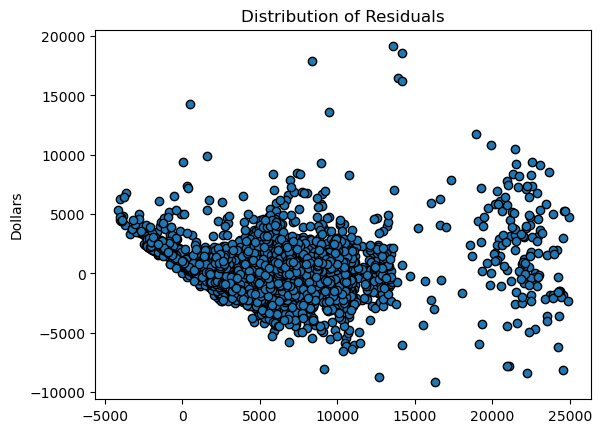

In [46]:
# electrical cost vs psi + hours + water total + fuel_rate + metered demand - using filtered data
endog = filtered_df["Electrical Bill"]
exog = filtered_df[["PSI", "Hours", "Water Total", "Fuel Rate", "Metered DM"]]
exog = sm.add_constant(exog)
lm = sm.OLS(endog, exog).fit()
print("Electrical bill costs explained by PSI, run hours, water total, fuel rate, and metered DM", lm.summary())

fig, ax = plt.subplots()
ax.scatter(lm.fittedvalues, lm.resid, edgecolor="black")
ax.set_ylabel("Dollars")
ax.set_title("Distribution of Residuals")
fig.show()

Electrical bill costs explained by fuel rate                             OLS Regression Results                            
Dep. Variable:        Electrical Bill   R-squared:                       0.021
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     148.4
Date:                Wed, 02 Sep 2026   Prob (F-statistic):           8.82e-34
Time:                        13:15:09   Log-Likelihood:                -67259.
No. Observations:                6905   AIC:                         1.345e+05
Df Residuals:                    6903   BIC:                         1.345e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const  

C:\Users\jroland\AppData\Local\Temp\ipykernel_8596\1942533182.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


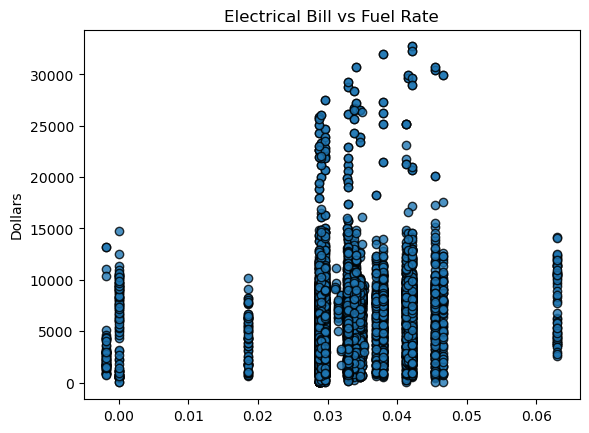

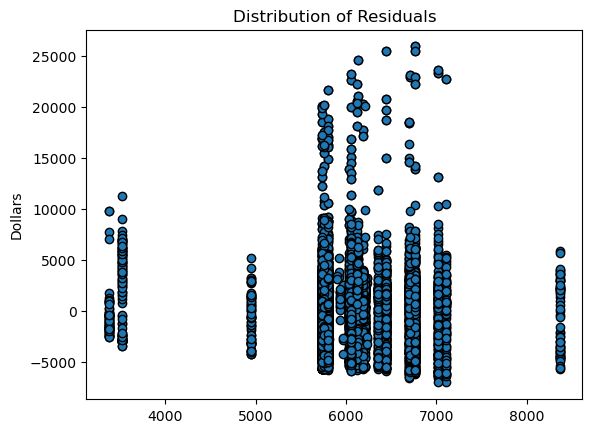

In [53]:
# electrical cost vs fuel_rate - using filtered data
endog = filtered_df["Electrical Bill"]
exog = filtered_df["Fuel Rate"]
exog = sm.add_constant(exog)
lm = sm.OLS(endog, exog).fit()
print("Electrical bill costs explained by fuel rate", lm.summary())

fig, ax = plt.subplots()
ax.scatter(filtered_df["Fuel Rate"], filtered_df["Electrical Bill"], edgecolor="black", alpha=0.8)
ax.set_ylabel("Dollars")
ax.set_title("Electrical Bill vs Fuel Rate")

fig, ax = plt.subplots()
ax.scatter(lm.fittedvalues, lm.resid, edgecolor="black")
ax.set_ylabel("Dollars")
ax.set_title("Distribution of Residuals")
fig.show()


Electrical bill costs explained by metered demand                             OLS Regression Results                            
Dep. Variable:        Electrical Bill   R-squared:                       0.673
Model:                            OLS   Adj. R-squared:                  0.673
Method:                 Least Squares   F-statistic:                 1.422e+04
Date:                Wed, 02 Sep 2026   Prob (F-statistic):               0.00
Time:                        13:15:39   Log-Likelihood:                -63472.
No. Observations:                6905   AIC:                         1.269e+05
Df Residuals:                    6903   BIC:                         1.270e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
co

C:\Users\jroland\AppData\Local\Temp\ipykernel_8596\2574750465.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


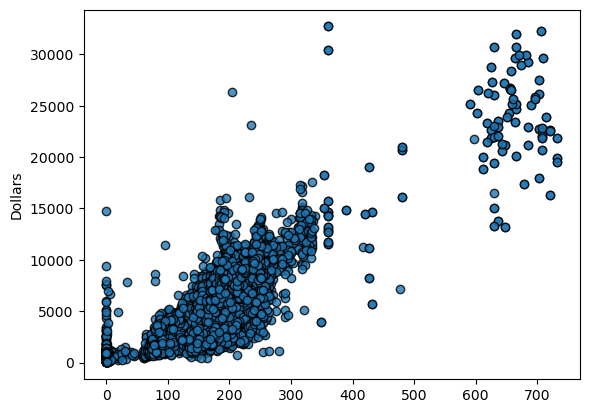

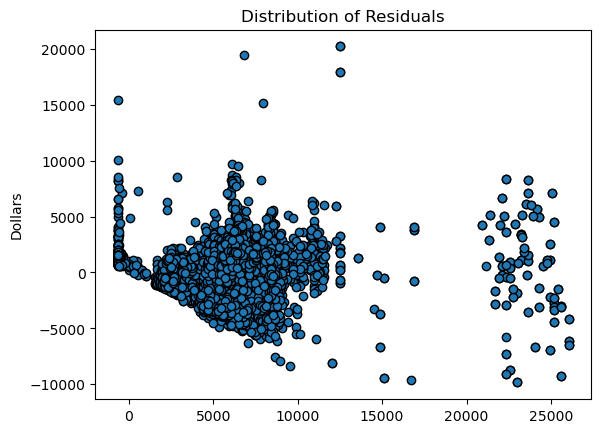

In [54]:
# electrical cost vs metered DM - using filtered data
endog = filtered_df["Electrical Bill"]
exog = filtered_df["Metered DM"]
exog = sm.add_constant(exog)
lm = sm.OLS(endog, exog).fit()
print("Electrical bill costs explained by metered demand", lm.summary())

fig, ax = plt.subplots()
ax.scatter(filtered_df["Metered DM"], filtered_df["Electrical Bill"], edgecolor="black", alpha=0.8)
ax.set_ylabel("Dollars")

fig, ax = plt.subplots()
ax.scatter(lm.fittedvalues, lm.resid, edgecolor="black")
ax.set_ylabel("Dollars")
ax.set_title("Distribution of Residuals")
fig.show()

Electrical bill costs explained by power factor                             OLS Regression Results                            
Dep. Variable:        Electrical Bill   R-squared:                       0.042
Model:                            OLS   Adj. R-squared:                  0.042
Method:                 Least Squares   F-statistic:                     303.5
Date:                Wed, 02 Sep 2026   Prob (F-statistic):           1.46e-66
Time:                        13:16:00   Log-Likelihood:                -67183.
No. Observations:                6905   AIC:                         1.344e+05
Df Residuals:                    6903   BIC:                         1.344e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------


C:\Users\jroland\AppData\Local\Temp\ipykernel_8596\2444689548.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


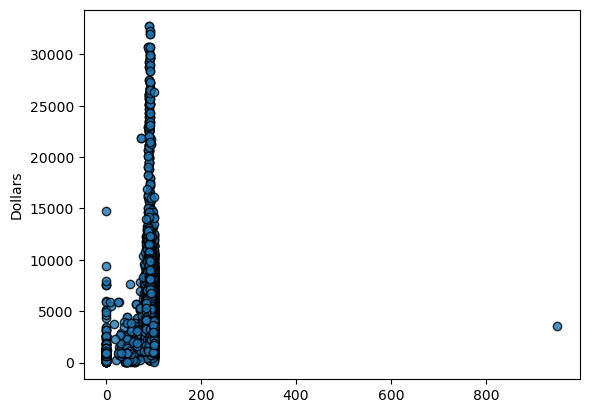

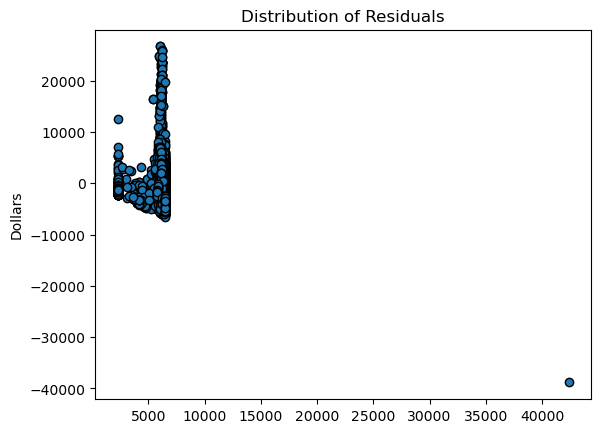

In [55]:
# electrical cost vs power factor - using filtered data
endog = filtered_df["Electrical Bill"]
exog = filtered_df["Power Factor"]
exog = sm.add_constant(exog)
lm = sm.OLS(endog, exog).fit()
print("Electrical bill costs explained by power factor", lm.summary())

fig, ax = plt.subplots()
ax.scatter(filtered_df["Power Factor"], filtered_df["Electrical Bill"], edgecolor="black", alpha=0.8)
ax.set_ylabel("Dollars")

fig, ax = plt.subplots()
ax.scatter(lm.fittedvalues, lm.resid, edgecolor="black")
ax.set_ylabel("Dollars")
ax.set_title("Distribution of Residuals")
fig.show()

PSI explained by Metered DM                             OLS Regression Results                            
Dep. Variable:                    PSI   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     46.37
Date:                Wed, 02 Sep 2026   Prob (F-statistic):           1.06e-11
Time:                        14:23:43   Log-Likelihood:                -44878.
No. Observations:                6905   AIC:                         8.976e+04
Df Residuals:                    6903   BIC:                         8.977e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        748.8143   

C:\Users\jroland\AppData\Local\Temp\ipykernel_8596\2533790192.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


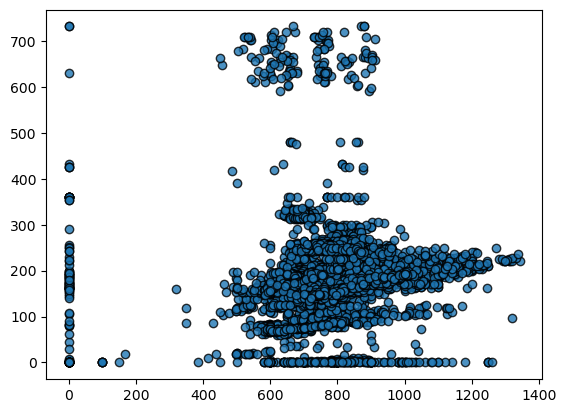

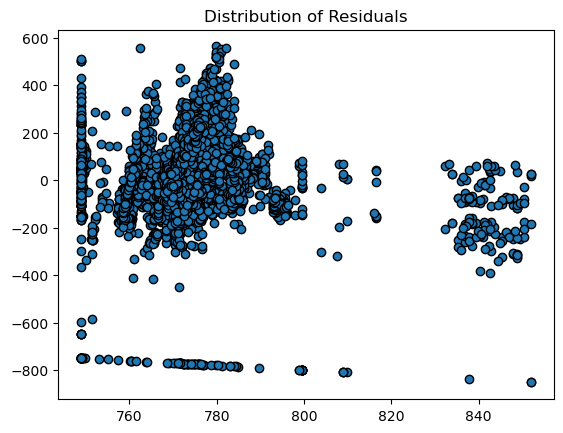

In [59]:
# electrical cost vs power factor - using filtered data
endog = filtered_df["PSI"]
exog = filtered_df["Metered DM"]
exog = sm.add_constant(exog)
lm = sm.OLS(endog, exog).fit()
print("PSI explained by Metered DM", lm.summary())

fig, ax = plt.subplots()
ax.scatter(filtered_df["PSI"], filtered_df["Metered DM"], edgecolor="black", alpha=0.8)

fig, ax = plt.subplots()
ax.scatter(lm.fittedvalues, lm.resid, edgecolor="black")
ax.set_title("Distribution of Residuals")
fig.show()

In [8]:
# Standard Linear Regression
# PREDICTIVE
# Exploration of KWH and billing relationships
# Variables of interest: Predictors: Hours, Water Total, PSI, Metered DM, Power Factor, Billed DM, Fuel Rate
#                        Predicted: Billing KWH
predictors = ["Hours", "Water Total", "PSI", "Metered DM", "Power Factor", "Billed DM", "Fuel Rate"]
predicted = ["Billing KWH",]

# We need to split dataset based on time, rather than randomly. The last observation for the data is September 2025.
# Let's attempt to predict 6 months worth of data, so the training set will be start -> March 2025
X = main_df[predictors]
y = main_df[predicted]

print(main_df["Year-Month"])

train_X = main_df[main_df["Year-Month"] < "2025-04"]
train_X = train_X[predictors]

test_X = main_df[main_df["Year-Month"] >= "2025-04"]
test_X = test_X[predictors]

train_y = main_df[main_df["Year-Month"] < "2025-04"]
train_y = train_y[predicted]

test_y = main_df[main_df["Year-Month"] >= "2025-04"]
test_y = test_y[predicted]


# Normalization - NOTE: We are explaining rather than predicting in this case, so normalization should transform
#                       all data and not just the training data whose values are applied to the test data.
# NOTE: Normalization applies to PCA and other methods sensitive to absolute magnitude differences. 
#       OLS linear regression is not one of those.

0       2017-08
1       2017-09
2       2017-10
3       2017-11
4       2017-12
         ...   
8521    2025-05
8522    2025-06
8523    2025-07
8524    2025-08
8525    2025-09
Name: Year-Month, Length: 8526, dtype: object


In [ ]:
# Principle Components Analysis
# Principle Components Regression 